# Klike Data Science Challenge
## Parte 2 — Modelagem Preditiva do Klike Score

**Empresa:** Millai | Klike  
**Dataset:** `klike_challenge_dataset.csv`  
**Linguagem:** Python  
**Objetivo:** desenvolver e avaliar modelos de regressão para estimar a qualidade de criativos publicitários.

---

### Contextualização

Na Parte 1, foi realizada uma análise exploratória de 500 campanhas publicitárias, investigando a qualidade dos dados, distribuições, valores ausentes, inconsistências e associações entre características dos criativos e métricas de desempenho.

Os resultados identificaram associações relevantes envolvendo a presença de *hook*, rosto humano, legendas, CTA e densidade de texto, além de diferenças entre plataformas.

Nesta segunda etapa, o objetivo é utilizar as características das campanhas para desenvolver um modelo capaz de prever o **Klike Score**, uma pontuação de 0 a 100 que representa a qualidade geral de um criativo segundo o sistema de avaliação da plataforma.

A modelagem priorizará atributos disponíveis antes da veiculação, permitindo avaliar o potencial de aplicação do modelo como ferramenta de apoio à criação e otimização de anúncios.

### Metodologia da modelagem

O desenvolvimento será organizado nas seguintes etapas:

1. **Preparação dos dados:** carregamento do dataset e definição das variáveis explicativas e da variável-alvo.
2. **Feature Engineering:** seleção das características relevantes, tratamento de valores ausentes, codificação de variáveis categóricas e avaliação de novos atributos.
3. **Separação treino/teste:** divisão dos registros para permitir uma avaliação em dados não utilizados no treinamento.
4. **Baseline:** construção de um modelo de referência para estabelecer o desempenho mínimo de comparação.
5. **Treinamento:** desenvolvimento e comparação de modelos de regressão.
6. **Avaliação:** análise das métricas MAE, RMSE e R², com interpretação da capacidade preditiva.
7. **Interpretabilidade:** identificação das variáveis mais relevantes para as previsões e discussão de sua aplicação ao negócio.

**Princípio metodológico:** as transformações que aprendem parâmetros dos dados, como imputação e codificação de categorias, serão ajustadas exclusivamente sobre os dados de treinamento, evitando vazamento de informação (*data leakage*). O conjunto de teste será preservado para a avaliação final.

In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Configuração visual
sns.set_theme(style="whitegrid", palette="Blues")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

RANDOM_STATE = 42


---

## 1. Preparação dos dados

### 1.1. Carregamento e verificação inicial

O dataset original será carregado novamente, garantindo que a modelagem seja independente da execução do notebook exploratório.

Nesta etapa, serão verificados o número de registros, a quantidade de variáveis, os tipos de dados e a presença de valores ausentes.

Como a análise exploratória identificou inconsistências em algumas métricas operacionais, o modelo inicial utilizará apenas atributos disponíveis antes da veiculação, reduzindo a dependência dessas métricas e evitando o uso de informações futuras.

In [18]:

# Carregamento dos dados originais
df = pd.read_csv("klike_challenge_dataset.csv")

# Visão geral do dataset
print(f"Registros: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")
print(f"Valores ausentes: {df.isna().sum().sum()}")
print(f"Campanhas duplicadas: {df['campaign_id'].duplicated().sum()}")

# Exibição das primeiras linhas
display(df.head())


Registros: 500
Colunas: 26
Valores ausentes: 235
Campanhas duplicadas: 0


,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,has_cta,has_hook,has_face,text_density,music_voice_ratio,impressions,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
0,KLK-0001,2024-01-01,Meta,Branding,awareness,18-24,False,NaN,vertical,True,True,False,True,medium,0.39,150825,5882,0.0390,0.82,4823.24,48,0.00,0.00,3.9,0.0446,63.6
1,KLK-0002,2024-03-22,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,True,True,True,low,0.07,7433,493,0.0664,3.54,1745.22,34,NaN,0.16,6.4,0.0217,70.0
2,KLK-0003,2024-05-04,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,True,True,True,medium,0.43,193198,15069,0.0780,0.38,5726.22,492,51053.44,8.92,8.0,0.1000,99.1
3,KLK-0004,2024-12-27,TikTok,Lead Gen,engagement,25-34,False,27.0,quadrado,False,True,True,True,medium,0.54,6506,601,0.0925,0.71,426.71,19,1113.78,2.61,20.3,0.0414,74.9
4,KLK-0005,2024-07-10,Meta,Branding,engagement,25-34,False,34.0,vertical,True,True,True,True,low,0.35,63830,2355,0.0369,0.38,894.90,13,0.00,0.00,34.0,0.0184,77.9


### 1.2. Definição das variáveis preditoras

A variável-alvo da modelagem será `klike_score`, representando a pontuação de qualidade do criativo.

Para as variáveis explicativas (*features*), será adotada uma abordagem orientada ao uso do modelo antes da veiculação da campanha.

**Variáveis selecionadas:**

| Grupo | Variáveis | Justificativa |
|---|---|---|
| Contexto da campanha | `platform`, `category`, `objective`, `target_audience_age`, `is_retargeting` | Representam o ambiente, o público e a finalidade do anúncio. |
| Características do vídeo | `video_duration_s`, `format`, `text_density`, `music_voice_ratio` | Descrevem propriedades estruturais e audiovisuais do criativo. |
| Elementos criativos | `has_subtitle`, `has_cta`, `has_hook`, `has_face` | Identificam recursos cuja presença pode estar associada à qualidade do anúncio. |

**Variáveis excluídas:**

- `campaign_id`: identificador administrativo, sem relevância preditiva esperada para novas campanhas.
- `date`: excluída inicialmente para simplificar a modelagem e evitar dependência de padrões temporais específicos.
- Métricas pós-veiculação, como `impressions`, `clicks`, `ctr`, `cpc`, `spend`, `conversions`, `revenue`, `roas`, `avg_watch_time_s` e `engagement_rate`: dependem de resultados observados após a publicação.

Essa seleção permite investigar quanto da variação do Klike Score pode ser explicado exclusivamente pelas características da campanha e do criativo.

A escolha também facilita a futura implementação de um sistema de recomendações, pois parte das variáveis representa atributos que podem ser modificados antes da publicação.

**Observação:** a seleção inicial poderá ser revisada após a avaliação dos modelos. Associações identificadas na análise exploratória não representam, necessariamente, relações causais.

In [19]:

# Variável-alvo
target = "klike_score"

# Características disponíveis antes da veiculação
features = [
    "platform",
    "category",
    "objective",
    "target_audience_age",
    "is_retargeting",
    "video_duration_s",
    "format",
    "has_subtitle",
    "has_cta",
    "has_hook",
    "has_face",
    "text_density",
    "music_voice_ratio"
]

# Separação entre variáveis explicativas e alvo
X = df[features].copy()
y = df[target].copy()

print(f"Quantidade de features: {X.shape[1]}")
print(f"Quantidade de registros: {X.shape[0]}")
print(f"Valores ausentes no target: {y.isna().sum()}")

display(X.head())


Quantidade de features: 13
Quantidade de registros: 500
Valores ausentes no target: 0


,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,has_cta,has_hook,has_face,text_density,music_voice_ratio
0,Meta,Branding,awareness,18-24,False,NaN,vertical,True,True,False,True,medium,0.39
1,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,True,True,True,low,0.07
2,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,True,True,True,medium,0.43
3,TikTok,Lead Gen,engagement,25-34,False,27.0,quadrado,False,True,True,True,medium,0.54
4,Meta,Branding,engagement,25-34,False,34.0,vertical,True,True,True,True,low,0.35


### 1.3. Inspeção das variáveis selecionadas

Antes de iniciar o pré-processamento, serão examinados os tipos das variáveis explicativas e a quantidade de valores ausentes.

Essa inspeção permitirá definir as transformações necessárias para cada grupo de atributos:

- **Variáveis numéricas:** tratamento de valores ausentes por imputação.
- **Variáveis categóricas:** codificação para representação numérica.
- **Variáveis booleanas:** padronização para valores binários, preservando os valores ausentes.

As transformações serão implementadas posteriormente em um pipeline, garantindo sua aplicação consistente durante o treinamento e a previsão.

In [20]:

# Resumo das features selecionadas
resumo_features = pd.DataFrame({
    "Tipo": X.dtypes.astype(str),
    "Valores ausentes": X.isna().sum(),
    "% ausente": (X.isna().mean() * 100).round(2),
    "Valores únicos": X.nunique(dropna=True)
})

display(resumo_features)

# Inspeção das variáveis booleanas
colunas_booleanas = [
    "is_retargeting",
    "has_subtitle",
    "has_cta",
    "has_hook",
    "has_face"
]

for coluna in colunas_booleanas:
    print(f"\n{coluna}")
    print(X[coluna].value_counts(dropna=False))


,Tipo,Valores ausentes,% ausente,Valores únicos
platform,str,0,0.0,3
category,str,0,0.0,5
objective,str,0,0.0,5
target_audience_age,str,0,0.0,4
is_retargeting,bool,0,0.0,2
video_duration_s,float64,39,7.8,56
format,str,0,0.0,3
has_subtitle,object,46,9.2,2
has_cta,bool,0,0.0,2
has_hook,bool,0,0.0,2



is_retargeting
is_retargeting
False    383
True     117
Name: count, dtype: int64

has_subtitle
has_subtitle
True     263
False    191
NaN       46
Name: count, dtype: int64

has_cta
has_cta
True     347
False    153
Name: count, dtype: int64

has_hook
has_hook
True     256
False    244
Name: count, dtype: int64

has_face
has_face
True     269
False    231
Name: count, dtype: int64


### 1.4. Separação dos dados em treinamento e teste

Para avaliar a capacidade de generalização dos modelos, o conjunto de dados será dividido em:

- **Treinamento (80%):** utilizado para ajustar os algoritmos e desenvolver os modelos preditivos.
- **Teste (20%):** reservado para avaliar o desempenho final em campanhas não utilizadas durante o treinamento.

A divisão será realizada com `random_state=42`, garantindo a reprodutibilidade dos resultados.

Como o objetivo inicial é estabelecer um modelo preditivo geral, será utilizada uma divisão aleatória. Uma avaliação temporal poderá ser considerada futuramente, caso a aplicação exija prever campanhas de períodos posteriores aos utilizados no treinamento.

O conjunto de teste não será utilizado para selecionar features, ajustar hiperparâmetros ou definir transformações.

In [21]:

from sklearn.model_selection import train_test_split

# Conversão de booleanos para valores numéricos
X_model = X.copy()

for coluna in colunas_booleanas:
    X_model[coluna] = X_model[coluna].map({
        True: 1,
        False: 0
    }).astype(float)

# Divisão treino/teste
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print(f"Registros de treinamento: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")

print(f"\nMédia do target no treino: {y_train.mean():.2f}")
print(f"Média do target no teste: {y_test.mean():.2f}")


Registros de treinamento: 400
Registros de teste: 100

Média do target no treino: 60.31
Média do target no teste: 59.54



### 1.5. Construção do pipeline de pré-processamento

Os modelos de regressão exigem que as variáveis explicativas sejam representadas numericamente e que os valores ausentes sejam tratados adequadamente.

Para isso, será utilizado um `ColumnTransformer`, permitindo aplicar transformações específicas a três grupos de variáveis.

**Variáveis numéricas:**

- Imputação pela mediana dos valores observados no treinamento.
- Padronização das variáveis contínuas para o modelo Ridge.

**Variáveis booleanas:**

- Imputação pela moda (valor mais frequente).
- Preservação da representação binária (0 ou 1).

**Variáveis categóricas:**

- Imputação pela moda caso existam valores ausentes.
- Aplicação de *One-Hot Encoding*, criando indicadores binários para cada categoria.
- Tratamento de categorias desconhecidas durante a previsão.

O pré-processamento será integrado aos modelos por meio de um `Pipeline` do scikit-learn.

Dessa forma, as transformações serão ajustadas exclusivamente com os dados de treinamento de cada fold, evitando *data leakage* e garantindo a reprodutibilidade do processo.


In [22]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Definição dos grupos de variáveis
features_numericas = [
    "video_duration_s",
    "music_voice_ratio"
]

features_categoricas = [
    "platform",
    "category",
    "objective",
    "target_audience_age",
    "format",
    "text_density"
]

# Pipeline das variáveis numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Pipeline das variáveis booleanas
pipeline_booleano = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

# Pipeline das variáveis categóricas
pipeline_categorico = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Transformador de pré-processamento
preprocessor = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico, features_numericas),
        ("bool", pipeline_booleano, colunas_booleanas),
        ("cat", pipeline_categorico, features_categoricas)
    ],
    remainder="drop"
)

print("Pré-processador configurado com sucesso.")
print(f"Features numéricas: {len(features_numericas)}")
print(f"Features booleanas: {len(colunas_booleanas)}")
print(f"Features categóricas: {len(features_categoricas)}")


Pré-processador configurado com sucesso.
Features numéricas: 2
Features booleanas: 5
Features categóricas: 6


In [23]:

# Verificação das variáveis atribuídas a cada grupo
features_processadas = (
    features_numericas
    + colunas_booleanas
    + features_categoricas
)

assert len(features_processadas) == len(set(features_processadas)), \
    "Existem features duplicadas entre os grupos."

assert set(features_processadas) == set(X_train.columns), \
    "Existem features não contempladas no pré-processamento."

print("Todas as features foram corretamente classificadas.")
print(f"Total de features originais: {len(features_processadas)}")
print(f"Total de nulos no treino (antes da imputação): {X_train.isna().sum().sum()}")
print(f"Total de nulos no teste (antes da imputação): {X_test.isna().sum().sum()}")


Todas as features foram corretamente classificadas.
Total de features originais: 13
Total de nulos no treino (antes da imputação): 97
Total de nulos no teste (antes da imputação): 26


---

## 2. Desenvolvimento dos Modelos Preditivos

### 2.1. Seleção dos algoritmos

Para prever o `klike_score`, serão avaliados três modelos de regressão com diferentes níveis de complexidade.

**Dummy Regressor — Baseline**

Modelo de referência que prevê a média do Klike Score observada nos dados de treinamento. Seu objetivo é estabelecer um desempenho mínimo para comparação.

**Ridge Regression — Modelo Linear Regularizado**

Regressão linear com regularização L2, que penaliza coeficientes excessivamente elevados. É uma alternativa adequada para avaliar relações aproximadamente lineares e controlar a complexidade diante das variáveis geradas pelo One-Hot Encoding.

**Random Forest Regressor — Modelo Não Linear**

Algoritmo baseado em um conjunto de árvores de decisão, capaz de identificar relações não lineares e interações entre características. Sua inclusão permite avaliar se padrões mais complexos melhoram a capacidade preditiva.

A comparação permitirá investigar se o aumento da complexidade resulta em ganhos relevantes de desempenho.

Os modelos serão inicialmente avaliados por validação cruzada, utilizando exclusivamente os dados de treinamento.

### 2.2. Métricas de avaliação

Para avaliar o desempenho preditivo, serão utilizadas três métricas complementares:

| Métrica | Interpretação | Resultado desejado |
|---|---|---|
| MAE | Erro absoluto médio das previsões, em pontos do Klike Score. | Menor |
| RMSE | Raiz do erro quadrático médio, que penaliza mais intensamente erros elevados. | Menor |
| R² | Proporção da variabilidade do target explicada pelo modelo em relação à previsão pela média. | Maior |

Como o Klike Score varia de 0 a 100, o MAE e o RMSE podem ser interpretados diretamente em pontos da escala utilizada pela plataforma.

Um R² próximo de 1 indica maior capacidade explicativa, enquanto valores próximos de 0 indicam desempenho semelhante ao modelo que prevê a média. Valores negativos indicam desempenho inferior a essa referência no conjunto avaliado.

### Estratégia de validação

Será utilizada validação cruzada com 5 folds (*K-Fold Cross-Validation*), embaralhamento dos registros e semente aleatória fixa.

Em cada iteração, o modelo será treinado em quatro partes dos dados de treinamento e avaliado na parte restante.

As transformações de pré-processamento serão ajustadas novamente dentro de cada fold, evitando vazamento de informações entre treinamento e validação.

O conjunto de teste permanecerá reservado para a avaliação final.

In [24]:

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_validate

# Configuração da validação cruzada
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Métricas de avaliação
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Pré-processamento para Ridge:
# padronização apenas das features numéricas contínuas
preprocessor_ridge = clone(preprocessor)

preprocessor_ridge.set_params(
    num=Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
)


# Definição dos modelos
modelos = {
    "Dummy Regressor": DummyRegressor(
        strategy="mean"
    ),

    "Ridge Regression": Pipeline(steps=[
        ("preprocessor", preprocessor_ridge),
        ("model", Ridge(alpha=1.0))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ])
}

# Avaliação dos modelos
resultados = []

for nome, modelo in modelos.items():

    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    resultados.append({
        "Modelo": nome,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R²": scores["test_R2"].mean(),
        "Desvio MAE": scores["test_MAE"].std()
    })

# Comparação dos resultados
df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    by="MAE"
).reset_index(drop=True)

display(df_resultados.round(3))


,Modelo,MAE,RMSE,R²,Desvio MAE
0,Ridge Regression,7.027,8.791,0.668,0.477
1,Random Forest,7.596,9.650,0.599,0.273
2,Dummy Regressor,12.703,15.679,-0.018,1.111


### 2.3. Comparação do desempenho dos modelos

Os resultados da validação cruzada serão comparados para identificar qual algoritmo apresenta melhor capacidade de generalização.

O **MAE será adotado como métrica principal**, por permitir interpretar diretamente o erro médio em pontos do Klike Score.

O RMSE será utilizado como métrica complementar, permitindo avaliar a presença de erros de previsão mais elevados. O R² ajudará a compreender a variabilidade do score explicada pelos modelos.

Além dos valores médios, será observada a variação do MAE entre os folds, buscando identificar possíveis sinais de instabilidade.

A escolha do modelo considerará não apenas sua precisão, mas também sua complexidade e interpretabilidade, especialmente diante da futura implementação do sistema de recomendações.

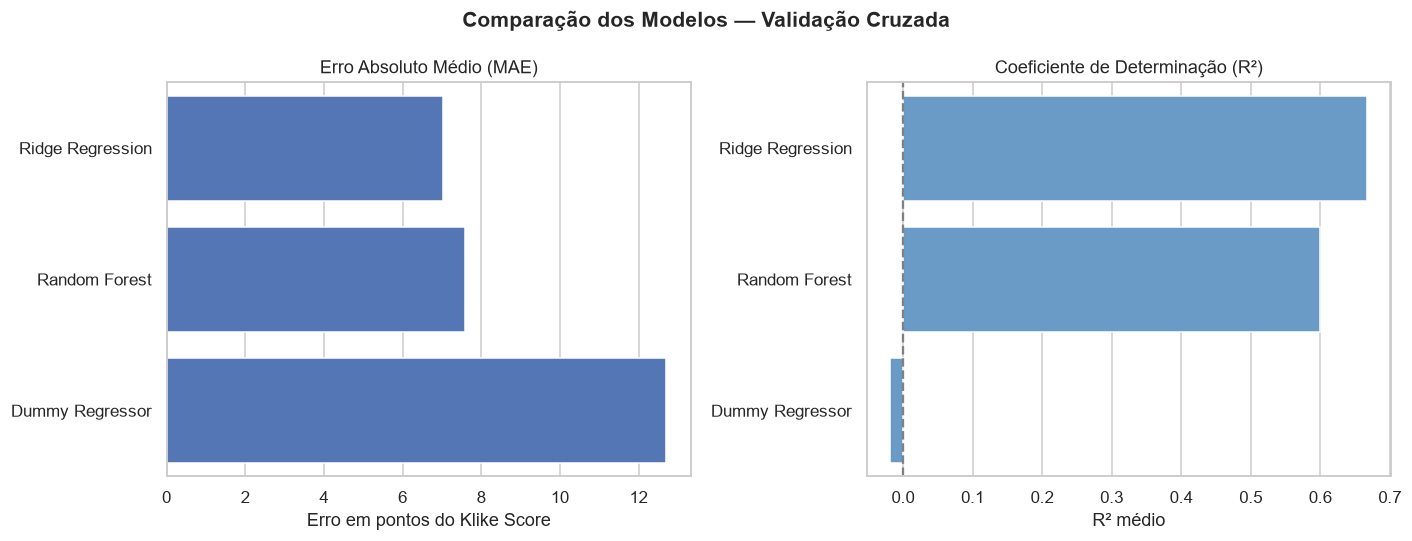

In [25]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Comparação do MAE
sns.barplot(
    data=df_resultados,
    x="MAE",
    y="Modelo",
    ax=axes[0],
    color="#4472C4"
)

axes[0].set_title("Erro Absoluto Médio (MAE)")
axes[0].set_xlabel("Erro em pontos do Klike Score")
axes[0].set_ylabel("")

# Comparação do R²
sns.barplot(
    data=df_resultados,
    x="R²",
    y="Modelo",
    ax=axes[1],
    color="#5B9BD5"
)

axes[1].axvline(0, color="gray", linestyle="--")
axes[1].set_title("Coeficiente de Determinação (R²)")
axes[1].set_xlabel("R² médio")
axes[1].set_ylabel("")

plt.suptitle(
    "Comparação dos Modelos — Validação Cruzada",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### 2.4. Otimização do Ridge Regression

Após a comparação inicial, o Ridge Regression apresentou o melhor desempenho entre os modelos avaliados, com MAE médio de 7,027 e R² médio de 0,668.

Diante desses resultados, será realizado um ajuste do hiperparâmetro `alpha`, responsável por controlar a intensidade da regularização L2.

A otimização será conduzida com `GridSearchCV`, avaliando um conjunto limitado de valores de `alpha` por validação cruzada com 5 folds.

O MAE será utilizado como critério de seleção, priorizando a redução do erro absoluto médio das previsões.

A busca será realizada exclusivamente sobre os dados de treinamento, preservando o conjunto de teste para a avaliação final.

O objetivo não é maximizar a complexidade do modelo, mas identificar uma configuração que apresente um bom equilíbrio entre precisão, simplicidade e capacidade de generalização.

In [26]:

from sklearn.model_selection import GridSearchCV

# Valores de alpha a serem avaliados
param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

# Configuração da busca
grid_search = GridSearchCV(
    estimator=clone(modelos["Ridge Regression"]),
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Busca utilizando apenas os dados de treinamento
grid_search.fit(X_train, y_train)

# Organização dos resultados
resultados_alpha = pd.DataFrame({
    "Alpha": grid_search.cv_results_["param_model__alpha"].astype(float),
    "MAE médio": -grid_search.cv_results_["mean_test_score"],
    "Desvio MAE": grid_search.cv_results_["std_test_score"]
})

resultados_alpha = resultados_alpha.sort_values(
    by="MAE médio"
).reset_index(drop=True)

display(resultados_alpha.round(3))

print(f"Melhor alpha: {grid_search.best_params_['model__alpha']}")
print(f"Melhor MAE médio: {-grid_search.best_score_:.3f}")


,Alpha,MAE médio,Desvio MAE
0,1.00,7.027,0.477
1,0.10,7.032,0.483
2,0.01,7.033,0.483
3,10.00,7.137,0.438
4,100.00,9.261,0.727


Melhor alpha: 1
Melhor MAE médio: 7.027


### 2.5. Análise da importância das variáveis

Após a comparação e otimização dos modelos, o Ridge Regression foi selecionado como candidato principal, com `alpha=1` e MAE médio de 7,027 pontos.

Nesta etapa, será investigado quais características apresentam maior contribuição para a capacidade preditiva do modelo.

Para isso, será utilizado o método **Permutation Importance**, que mede a deterioração do desempenho ao embaralhar individualmente os valores de uma variável, mantendo as demais características inalteradas.

A importância será calculada utilizando o MAE como referência:

- **Importância positiva:** a alteração da variável aumenta o erro, indicando contribuição para a previsão.
- **Importância próxima de zero:** a variável apresenta pouca contribuição adicional para o modelo avaliado.
- **Importância negativa:** o embaralhamento reduz o erro, podendo indicar instabilidade ou uma variável pouco útil.

A análise será realizada nos conjuntos de validação dos 5 folds, utilizando apenas os registros de treinamento.

É importante destacar que a importância preditiva não representa um efeito causal. Uma variável pode ser relevante para prever o Klike Score sem que sua alteração provoque necessariamente uma melhoria na qualidade ou no desempenho real de um anúncio.

In [27]:

from sklearn.inspection import permutation_importance

# Modelo selecionado após otimização
melhor_modelo = clone(grid_search.best_estimator_)

importancias_folds = []

# Importância calculada em validação cruzada
for treino_idx, validacao_idx in cv.split(X_train):

    X_treino_fold = X_train.iloc[treino_idx]
    X_validacao_fold = X_train.iloc[validacao_idx]

    y_treino_fold = y_train.iloc[treino_idx]
    y_validacao_fold = y_train.iloc[validacao_idx]

    modelo_fold = clone(melhor_modelo)

    modelo_fold.fit(X_treino_fold, y_treino_fold)

    resultado = permutation_importance(
        modelo_fold,
        X_validacao_fold,
        y_validacao_fold,
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    importancias_folds.append(
        resultado.importances_mean
    )

# Consolidação dos resultados
importancias_folds = np.array(importancias_folds)

df_importancia = pd.DataFrame({
    "Feature": X_train.columns,
    "Importância média": importancias_folds.mean(axis=0),
    "Desvio padrão": importancias_folds.std(axis=0)
})

df_importancia = df_importancia.sort_values(
    by="Importância média",
    ascending=False
).reset_index(drop=True)

display(df_importancia.round(3))


,Feature,Importância média,Desvio padrão
0,has_hook,5.423,0.354
1,has_face,2.713,0.719
2,text_density,2.066,0.439
3,has_subtitle,0.984,0.282
4,has_cta,0.914,0.340
5,platform,0.377,0.104
6,is_retargeting,0.308,0.124
7,category,0.237,0.151
8,format,0.113,0.089
9,music_voice_ratio,0.082,0.115


### 2.6. Visualização da importância das features

Para facilitar a interpretação dos resultados, as variáveis serão apresentadas em ordem decrescente de importância.

O gráfico permitirá identificar quais características mais contribuem para a qualidade das previsões do Ridge e quais apresentam menor relevância adicional.

A análise será utilizada para discutir a interpretabilidade do modelo e identificar possíveis atributos de interesse para o Recommendations Engine.

Como características correlacionadas podem compartilhar informação preditiva, valores baixos de importância não serão interpretados automaticamente como ausência de relevância para o negócio.

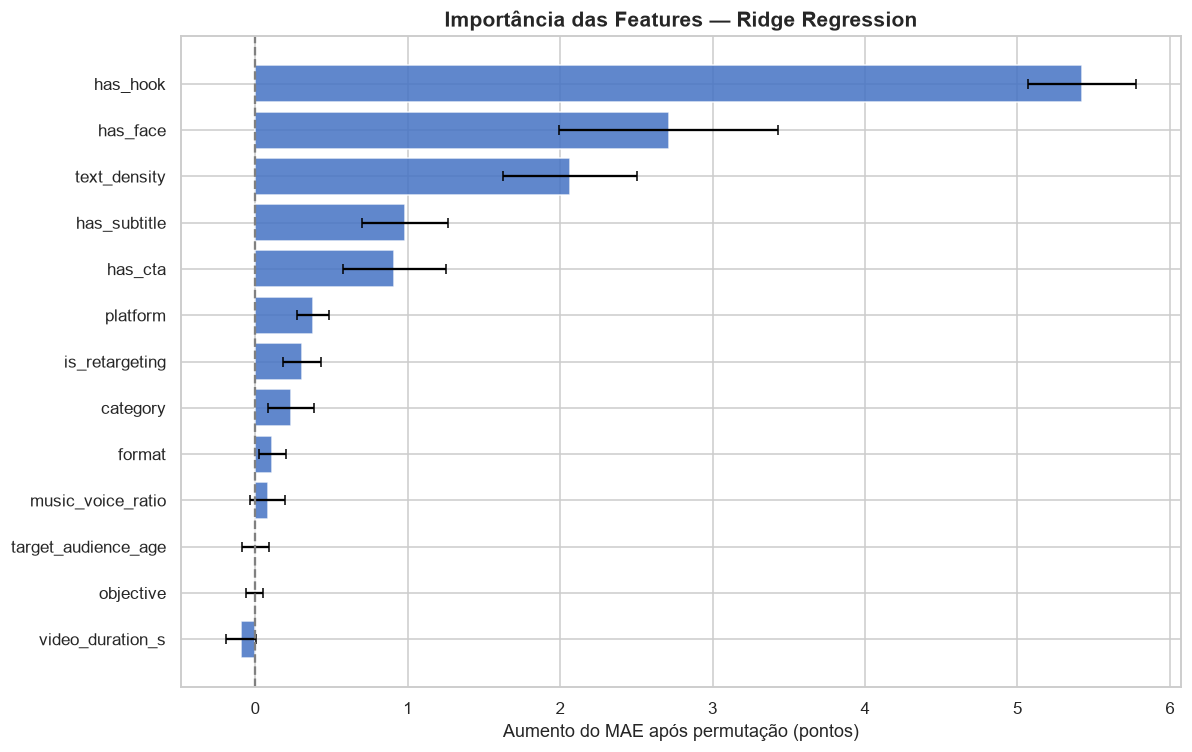

In [28]:

# Ordenação para visualização
df_plot = df_importancia.sort_values(
    by="Importância média",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    df_plot["Feature"],
    df_plot["Importância média"],
    xerr=df_plot["Desvio padrão"],
    color="#4472C4",
    alpha=0.85,
    capsize=3
)

ax.axvline(0, color="gray", linestyle="--")

ax.set_title(
    "Importância das Features — Ridge Regression",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Aumento do MAE após permutação (pontos)"
)

ax.set_ylabel("")

plt.tight_layout()
plt.show()


### 2.7. Diagnóstico de Overfitting

Após identificar as variáveis mais relevantes para as previsões, será investigada a capacidade de generalização do Ridge Regression.

O objetivo é verificar se o modelo apresenta desempenho consistente entre os dados utilizados no ajuste e os dados de validação.

Para isso, serão comparados os erros de treinamento e validação ao longo dos cinco folds.

Diferenças elevadas entre esses erros podem indicar overfitting, enquanto erros semelhantes sugerem maior estabilidade. Entretanto, essa comparação isolada não é suficiente para comprovar a ausência de overfitting.

A análise também auxiliará na decisão sobre uma possível redução da quantidade de features, buscando manter um modelo simples e com boa capacidade preditiva.

In [29]:

# Diagnóstico de overfitting com validação cruzada
scores_overfitting = cross_validate(
    clone(melhor_modelo),
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

df_overfitting = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE Treino": -scores_overfitting["train_MAE"],
    "MAE Validação": -scores_overfitting["test_MAE"],
    "R² Treino": scores_overfitting["train_R2"],
    "R² Validação": scores_overfitting["test_R2"]
})

df_overfitting["Gap MAE"] = (
    df_overfitting["MAE Validação"]
    - df_overfitting["MAE Treino"]
)

display(df_overfitting.round(3))

print("\nResumo:")
print(f"MAE médio treino: {df_overfitting['MAE Treino'].mean():.3f}")
print(f"MAE médio validação: {df_overfitting['MAE Validação'].mean():.3f}")
print(f"Gap médio de MAE: {df_overfitting['Gap MAE'].mean():.3f}")
print(f"Desvio MAE validação: {df_overfitting['MAE Validação'].std():.3f}")


,Fold,MAE Treino,MAE Validação,R² Treino,R² Validação,Gap MAE
0,1,6.448,6.781,0.727,0.734,0.333
1,2,6.557,6.442,0.733,0.708,-0.115
2,3,6.543,6.728,0.712,0.762,0.185
3,4,6.341,7.651,0.746,0.618,1.310
4,5,6.327,7.533,0.767,0.517,1.206



Resumo:
MAE médio treino: 6.443
MAE médio validação: 7.027
Gap médio de MAE: 0.584
Desvio MAE validação: 0.533


### 2.8. Avaliação de um modelo com menos features

O diagnóstico de overfitting apresentou uma diferença média de 0,584 ponto entre os erros de treinamento e validação, sem evidências fortes de sobreajuste.

Entretanto, a análise de importância revelou que algumas variáveis apresentaram contribuição preditiva muito pequena.

Para investigar se a simplificação pode melhorar a generalização, serão comparadas duas configurações do Ridge:

- **Modelo completo:** utiliza as 13 features originais.
- **Modelo reduzido:** remove `objective`, `target_audience_age` e `music_voice_ratio`, mantendo 10 features.

A seleção preliminar das variáveis removidas considera sua baixa importância preditiva observada anteriormente. A variável `video_duration_s` será mantida, apesar da baixa importância individual, por sua relevância para futuras recomendações sobre os criativos.

Ambos os modelos utilizarão `alpha=1`, o mesmo procedimento de pré-processamento e os mesmos cinco folds.

A comparação considerará o MAE, RMSE, R² e a diferença entre os erros de treinamento e validação.

**Limitação metodológica:** como a seleção das variáveis foi orientada por análises anteriores nos mesmos dados de treinamento, essa comparação será considerada exploratória. Seus resultados não constituem uma estimativa independente do ganho de generalização. O conjunto de teste permanecerá reservado para a avaliação final.

In [30]:

# Features selecionadas para o modelo reduzido
features_reduzidas = [
    coluna for coluna in features
    if coluna not in [
        "objective",
        "target_audience_age",
        "music_voice_ratio"
    ]
]

# Grupos de variáveis do modelo reduzido
numericas_reduzidas = [
    coluna for coluna in features_numericas
    if coluna in features_reduzidas
]

booleanas_reduzidas = [
    coluna for coluna in colunas_booleanas
    if coluna in features_reduzidas
]

categoricas_reduzidas = [
    coluna for coluna in features_categoricas
    if coluna in features_reduzidas
]

# Pré-processamento independente do modelo reduzido
preprocessor_reduzido = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numericas_reduzidas),

        ("bool", clone(pipeline_booleano), booleanas_reduzidas),

        ("cat", clone(pipeline_categorico), categoricas_reduzidas)
    ]
)

# Modelo Ridge reduzido
modelo_reduzido = Pipeline(steps=[
    ("preprocessor", preprocessor_reduzido),
    ("model", Ridge(alpha=1.0))
])

# Configurações a comparar
configuracoes = {
    "Ridge Completo": (
        clone(melhor_modelo),
        X_train
    ),
    "Ridge Reduzido": (
        modelo_reduzido,
        X_train[features_reduzidas]
    )
}

resultados_comparacao = []

for nome, (modelo, dados) in configuracoes.items():

    scores = cross_validate(
        modelo,
        dados,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    mae_treino = -scores["train_MAE"].mean()
    mae_validacao = -scores["test_MAE"].mean()

    resultados_comparacao.append({
        "Modelo": nome,
        "Nº Features": dados.shape[1],
        "MAE Treino": mae_treino,
        "MAE Validação": mae_validacao,
        "RMSE Validação": -scores["test_RMSE"].mean(),
        "R² Validação": scores["test_R2"].mean(),
        "Gap MAE": mae_validacao - mae_treino
    })

df_comparacao = pd.DataFrame(resultados_comparacao)

display(df_comparacao.round(3))


,Modelo,Nº Features,MAE Treino,MAE Validação,RMSE Validação,R² Validação,Gap MAE
0,Ridge Completo,13,6.443,7.027,8.791,0.668,0.584
1,Ridge Reduzido,10,6.533,6.915,8.658,0.676,0.382
